<a href="https://colab.research.google.com/github/inesnair/birdsfinder/blob/main/antilles_10especes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

connection au drive pour y sauvegarder les données (Colab efface tout à la fermeture),récup du code depuis GitHub et instal les bibliothèques train.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/inesnair/birdsfinder.git
%cd birdsfinder
!pip -q install -r requirements-train.txt

Mounted at /content/drive
Cloning into 'birdsfinder'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (121/121), done.
remote: Total 144 (delta 29), reused 57 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 271.41 KiB | 6.31 MiB/s, done.
Resolving deltas: 100% (29/29), done.
/content/birdsfinder


nouveau dossier pour version a 10 especes

In [ ]:
DRIVE = "/content/drive/MyDrive/birdsfinder"
OUT = f"{DRIVE}/data_antilles_10"

GBIF pour compter (Guadeloupe et Martinique) les photos d’oiseaux validées par iNaturalist sous licence libre. sortie : species_counts.csv avec 1 ligne par espèce, avec son nombre de photos.

In [ ]:
!python -m src.build_antilles_dataset count --out "$OUT" --fr-names --nc

import pandas as pd
counts = pd.read_csv(f"{OUT}/species_counts.csv")
counts[["canonical_name", "french_name", "guadeloupe", "martinique", "total"]].head(20)

GP : 4808 observations avec photo, 129 espèces
MQ : 7020 observations avec photo, 118 espèces
Récupération des noms de 157 espèces...

=> /content/drive/MyDrive/birdsfinder/data_antilles_10/species_counts.csv

Nombre d'espèces exploitables selon le seuil de photos par espèce :
  >=  30 photos : 57 espèces
  >=  60 photos : 39 espèces
  >= 100 photos : 32 espèces
  >= 150 photos : 22 espèces
  >= 300 photos : 12 espèces

Top 10 :
    990  Quiscalus lugubris  (GP 301 / MQ 689)
    738  Loxigilla noctis  (GP 287 / MQ 451)
    633  Zenaida aurita  (GP 224 / MQ 409)
    631  Tyrannus dominicensis  (GP 238 / MQ 393)
    588  Coereba flaveola  (GP 215 / MQ 373)
    515  Melanospiza bicolor  (GP 127 / MQ 388)
    493  Orthorhyncus cristatus  (GP 164 / MQ 329)
    414  Pelecanus occidentalis  (GP 200 / MQ 214)
    394  Bubulcus ibis  (GP 138 / MQ 256)
    386  Eulampis jugularis  (GP 129 / MQ 257)


,canonical_name,french_name,guadeloupe,martinique,total
0,Quiscalus lugubris,Quiscale merle,301,689,990
1,Loxigilla noctis,Pèrenoir rougegorge,287,451,738
2,Zenaida aurita,Tourterelle à queue carrée,224,409,633
3,Tyrannus dominicensis,Tyran gris,238,393,631
4,Coereba flaveola,"Sucrier à poitrine jaune, Sucrier à ventre jau...",215,373,588
5,Melanospiza bicolor,Cici verdinère,127,388,515
6,Orthorhyncus cristatus,Campyloptère huppé,164,329,493
7,Pelecanus occidentalis,Pélican brun,200,214,414
8,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",138,256,394
9,Eulampis jugularis,Colibri madère,129,257,386


lit la liste des espèces dans species_counts.csv. Je garde l’inventaire complet sous un autre nom, comme trace de mon choix, et je ne laisse dans species_counts.csv que mes 10 espèces.

In [ ]:
MES_10 = [
    "Quiscalus lugubris",      # Quiscale merle        piege car oiseaux noirs
    "Loxigilla noctis",        # Pèrenoir rougegorge   pareil
    "Melanospiza bicolor",     # Cici verdinère        idem
    "Tyrannus dominicensis",   # Tyran gris            iege car gris
    "Mimus gilvus",            # Moqueur des savanes   piege car gris
    "Orthorhyncus cristatus",  # Campyloptère huppé    facile car nombreux : colibris
    "Eulampis jugularis",      # Colibri madère        facile car nombreux : colibris
    "Bubulcus ibis",           # Héron garde-bœufs     piege car blanc (confondu avec aigrette dans les 1ers test)
    "Coereba flaveola",        # Sucrier à ventre jaune facile car coloré
    "Zenaida aurita",          # Tourterelle à queue carrée facil
]

counts.to_csv(f"{OUT}/species_counts_all.csv", index=False)   # inventaire complet, gardé comme preuve
selection = counts[counts["canonical_name"].isin(MES_10)]
selection.to_csv(f"{OUT}/species_counts.csv", index=False)
print(len(selection), "espèces retenues")                     # doit afficher 10
selection[["canonical_name", "french_name", "total"]]

10 espèces retenues


,canonical_name,french_name,total
0,Quiscalus lugubris,Quiscale merle,990
1,Loxigilla noctis,Pèrenoir rougegorge,738
2,Zenaida aurita,Tourterelle à queue carrée,633
3,Tyrannus dominicensis,Tyran gris,631
4,Coereba flaveola,"Sucrier à poitrine jaune, Sucrier à ventre jau...",588
5,Melanospiza bicolor,Cici verdinère,515
6,Orthorhyncus cristatus,Campyloptère huppé,493
8,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",394
9,Eulampis jugularis,Colibri madère,386
11,Mimus gilvus,Moqueur des savanes,343


telechargement jusqu'a 100 photos par espece. 1 observation = 1 photo. Vérif que chaque image n’est pas corrompue et la réduit à 640 px de côté, ce qui suffit pour un modèle qui travaille en 224 px

In [ ]:
!python -m src.build_antilles_dataset download --out "$OUT" --per-species 100 --nc

Pays : GP, MQ | licences : CC0_1_0, CC_BY_4_0, CC_BY_NC_4_0
10 espèces retenues (>= 60 photos).
[1/10] Quiscalus lugubris: 100/100 images
[2/10] Loxigilla noctis: 100/100 images
[3/10] Zenaida aurita: 100/100 images
[4/10] Tyrannus dominicensis: 100/100 images
[5/10] Coereba flaveola: 100/100 images
[6/10] Melanospiza bicolor: 100/100 images
[7/10] Orthorhyncus cristatus: 100/100 images
[8/10] Bubulcus ibis: 100/100 images
[9/10] Eulampis jugularis: 100/100 images
[10/10] Mimus gilvus: 100/100 images

Terminé : 1000 images, 0 échecs. Métadonnées : /content/drive/MyDrive/birdsfinder/data_antilles_10/metadata.csv


dataset brut : metadata.csv, 1 ligne par photo (espèce, pays, coordonnées GPS, date, auteur, licence, lien d’origine)

In [ ]:
meta = pd.read_csv(f"{OUT}/metadata.csv")
print(len(meta), "photos au total")
display(meta.groupby("french_name").size().sort_values(ascending=False).rename("nb_photos"))
display(meta.groupby("country").size().rename("nb_photos"))
meta.head()

1000 photos au total


,nb_photos
french_name,
Campyloptère huppé,100
Cici verdinère,100
Colibri madère,100
"Héron garde-boeufs, Pique bœufs",100
Moqueur des savanes,100
Pèrenoir rougegorge,100
Quiscale merle,100
"Sucrier à poitrine jaune, Sucrier à ventre jaune, Sucrier falle jaune, Sucrier cage",100
Tourterelle à queue carrée,100


,nb_photos
country,
GP,329
MQ,671


,species,french_name,species_key,local_path,occurrence_key,country,lat,lon,date,creator,license,source_url
0,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",2480830,images/Bubulcus_ibis/5007671652.jpg,5007671652,GP,16.482980,-61.501662,2025-01-05,Guillaume Martin,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
1,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",2480830,images/Bubulcus_ibis/5036692672.jpg,5036692672,GP,16.080286,-61.598547,2025-01-12,Guillaume Martin,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
2,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",2480830,images/Bubulcus_ibis/5037021875.jpg,5037021875,GP,16.249303,-61.283325,2025-01-13,Jessica K. Schnell,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
3,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",2480830,images/Bubulcus_ibis/5037273234.jpg,5037273234,GP,16.085658,-61.576218,2025-01-12,Guillaume Martin,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
4,Bubulcus ibis,"Héron garde-boeufs, Pique bœufs",2480830,images/Bubulcus_ibis/5063030401.jpg,5063030401,GP,16.182097,-61.589777,2025-01-13,Guillaume Martin,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...


vérifie qui fait les photos pour eviter doublon (photo du meme animal par le meme photographe le meme jour ou a X jour dintervalle)

In [ ]:
display(meta.groupby("creator").size().sort_values(ascending=False).head(10).rename("nb_photos"))

,nb_photos
creator,
Erika Mitchell,286
Derek Duplessis,90
nicovz,75
Guillaume Martin,47
chassignol,34
geoffrey-delahaye,32
Wolfgang Ahlmer,24
Aimie,14
oncapintada,14


Netteté : la variance du Laplacien, qui mesure la quantité de contours nets ; plus elle est basse, plus c’est flou. Luminosité : la moyenne des pixels. Empreinte visuelle : une signature de 64 bits ; deux photos aux empreintes presque identiques sont probablement des doublons. Ces indices ne rejettent rien, ils signalent

In [ ]:
import cv2
import numpy as np
from PIL import Image

meta["id"] = range(len(meta))                       # un numéro court par photo, pour la revue
meta["path"] = OUT + "/" + meta["local_path"]

def nettete_luminosite(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.Laplacian(g, cv2.CV_64F).var(), g.mean()

def empreinte(path, taille=8):
    g = Image.open(path).convert("L").resize((taille + 1, taille))
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()          # 64 bits : chaque pixel est-il plus clair que son voisin ?

mesures = [nettete_luminosite(p) for p in meta["path"]]
meta["nettete"] = [m[0] for m in mesures]
meta["luminosite"] = [m[1] for m in mesures]

empreintes = np.array([empreinte(p) for p in meta["path"]])
distances = (empreintes[:, None, :] != empreintes[None, :, :]).sum(axis=2)   # nb de bits différents
np.fill_diagonal(distances, 99)

SEUIL_FLOU = meta["nettete"].quantile(0.05)          # les 5 % les moins nettes

def alerte(i, r):
    motifs = []
    if r.nettete < SEUIL_FLOU: motifs.append("flou ?")
    if r.luminosite < 40: motifs.append("sombre ?")
    jumeaux = np.where(distances[i, :i] <= 5)[0]
    if len(jumeaux): motifs.append(f"doublon de {meta.id.iloc[jumeaux[0]]} ?")
    return ", ".join(motifs)

meta["alerte"] = [alerte(i, r) for i, r in enumerate(meta.itertuples())]
print((meta.alerte != "").sum(), "photos suspectes sur", len(meta))

52 photos suspectes sur 1000


affiche les photos de chaque espèce en mosaïques de 50 vignettes numérotées. Les photos signalées sont encadrées en rouge avec leur motif. Je les passe toutes en revue, pas seulement les rouge

In [ ]:
import matplotlib.pyplot as plt

def mosaique(espece, page=0, par_page=50, colonnes=10):
    sel = meta[meta["species"] == espece].iloc[page * par_page:(page + 1) * par_page]
    lignes = int(np.ceil(len(sel) / colonnes))
    fig, axes = plt.subplots(lignes, colonnes, figsize=(colonnes * 2.2, lignes * 2.4))
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
    for ax, r in zip(axes.flat, sel.itertuples()):
        ax.imshow(Image.open(r.path))
        suspecte = r.alerte != ""
        ax.set_title(f"{r.id}" + (f"\n{r.alerte}" if suspecte else ""), fontsize=9,
                     color="red" if suspecte else "black")
        if suspecte:
            for s in ax.spines.values(): s.set_visible(True); s.set_color("red"); s.set_linewidth(4)
    fig.suptitle(f"{sel.french_name.iloc[0]} — page {page + 1}", fontsize=14)
    plt.tight_layout(); plt.show()

for page in range(2):
  mosaique("Bubulcus ibis", page=page)    #affiche les 2 page donc 100 photo

photo a rejeter et motif

In [ ]:
REJETS = {
    2 : "sombre",
    7 : "luminosité donne un effet rose",
    47 : "vache au 1er plan",
    48 : "vache au 1er plan",
    50 : "vache",
    61 : "vache",
    71 : "tracteur",
    68 : "tracteur"
}

meta["statut"] = "gardée"
meta["motif"] = ""
for i, motif in REJETS.items():
    meta.loc[meta["id"] == i, ["statut", "motif"]] = ["rejetée", motif]

meta.drop(columns="path").to_csv(f"{OUT}/metadata_nettoye.csv", index=False)
display(meta.groupby(["french_name", "statut"]).size().unstack(fill_value=0))

statut,gardée,rejetée
french_name,,
Campyloptère huppé,100,0
Cici verdinère,100,0
Colibri madère,100,0
"Héron garde-boeufs, Pique bœufs",92,8
Moqueur des savanes,100,0
Pèrenoir rougegorge,100,0
Quiscale merle,100,0
"Sucrier à poitrine jaune, Sucrier à ventre jaune, Sucrier falle jaune, Sucrier cage",100,0
Tourterelle à queue carrée,100,0


Trop long : je passe a de l'extraction que des phot rouge 'a verifier'

44 photos à vérifier


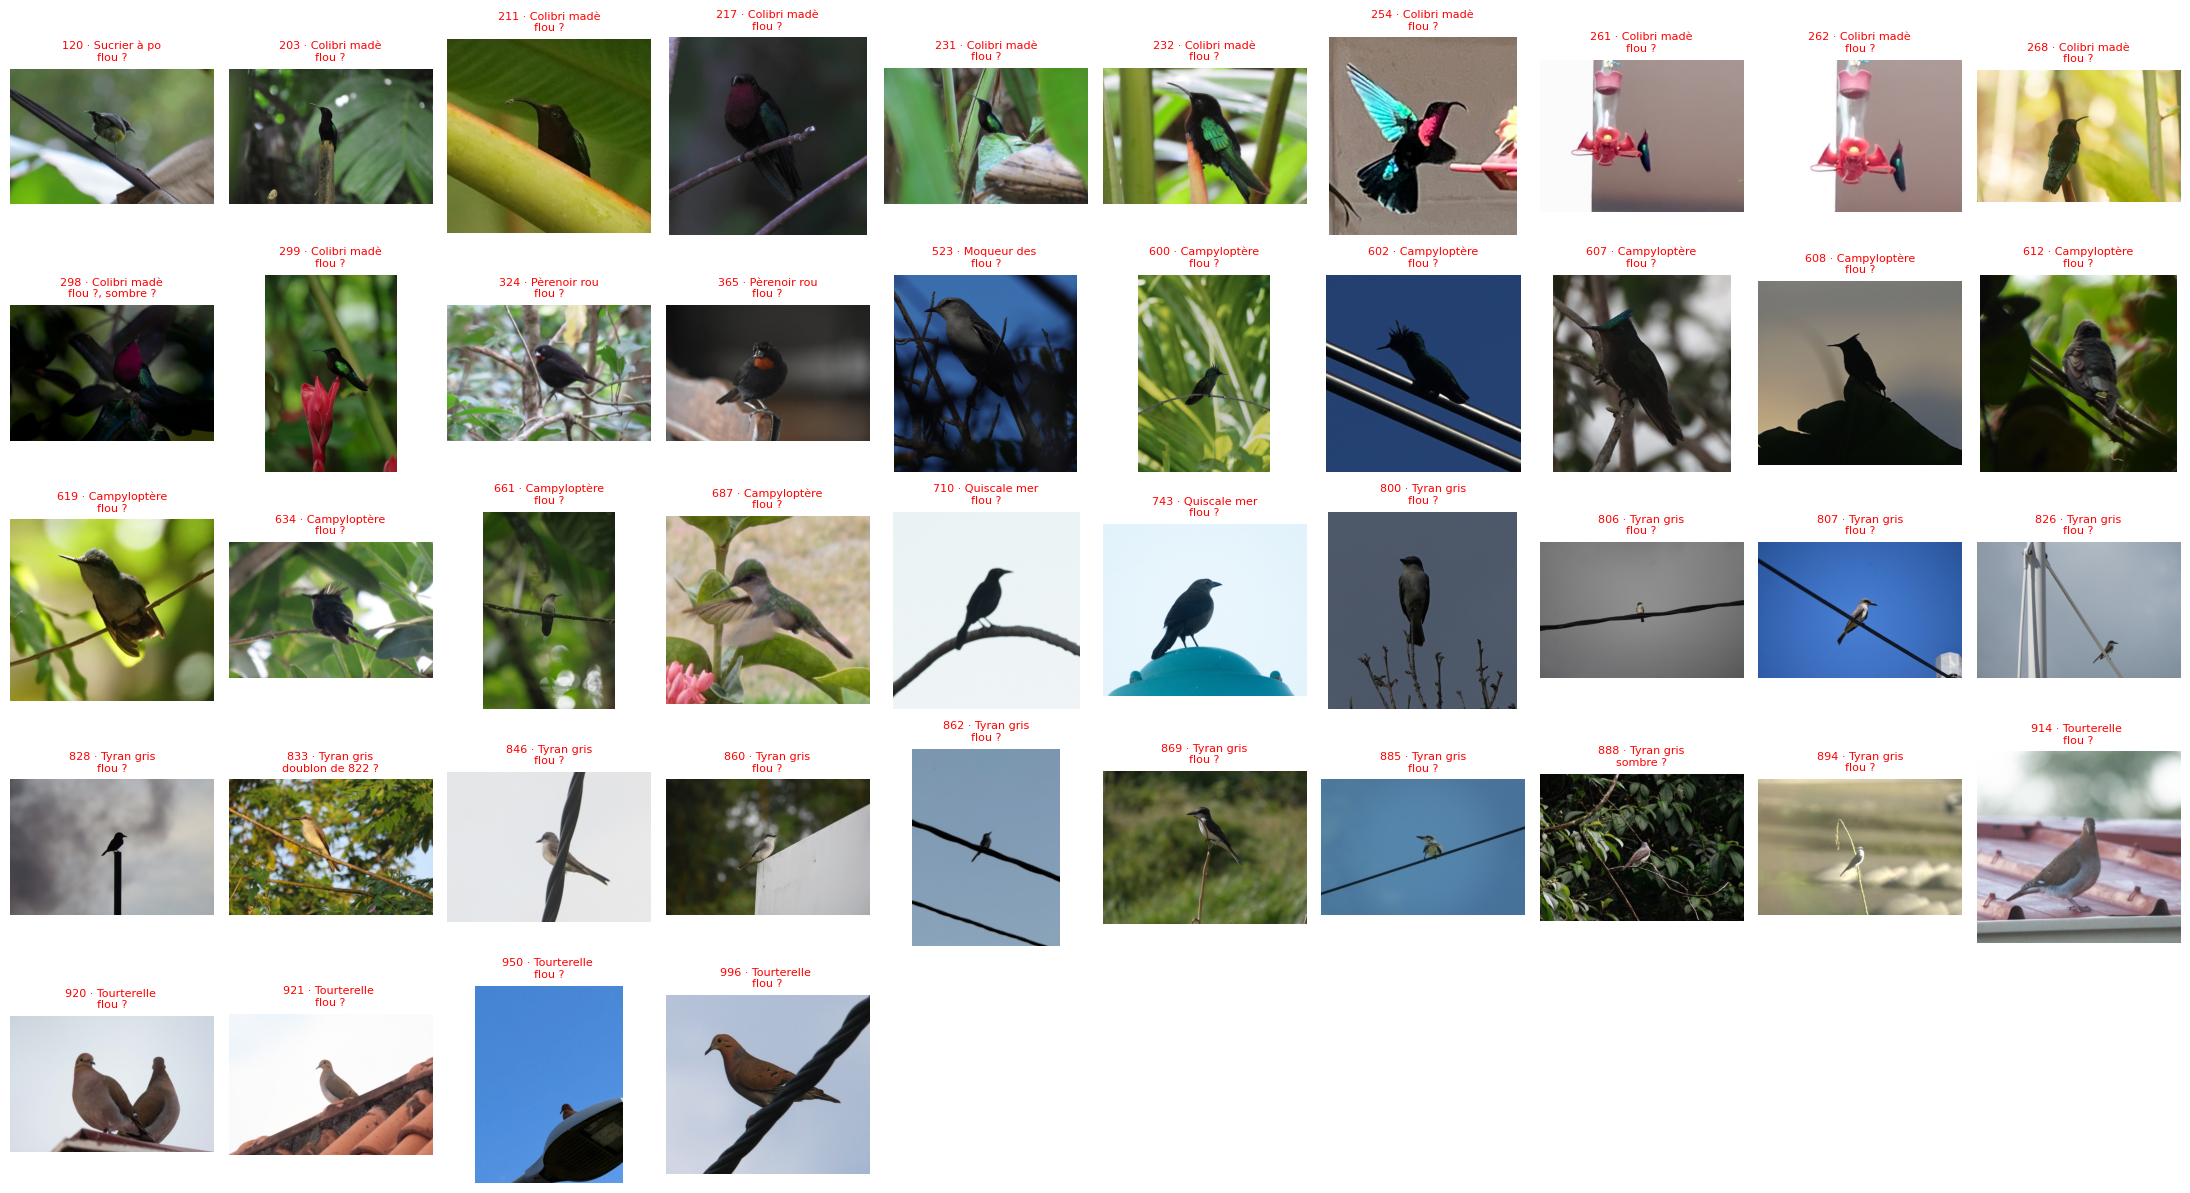

In [16]:
suspectes = meta[(meta.alerte != "") & (meta.species != "Bubulcus ibis")]
print(len(suspectes), "photos à vérifier")
for debut in range(0, len(suspectes), 50):
    sel = suspectes.iloc[debut:debut + 50]
    lignes = int(np.ceil(len(sel) / 10))
    fig, axes = plt.subplots(lignes, 10, figsize=(22, lignes * 2.4), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, r in zip(axes.flat, sel.itertuples()):
        ax.imshow(Image.open(r.path))
        ax.set_title(f"{r.id} · {r.french_name[:12]}\n{r.alerte}", fontsize=8, color="red")
    plt.tight_layout(); plt.show()

Suppression de toutes les photos floues

In [18]:
GARDER_QUAND_MEME = [

]

REJETS_MANUELS = {

}

meta["statut"] = "gardée"
meta["motif"] = ""

# Rejet de toutes les photos signalées, sauf les exceptions
auto = (meta["alerte"] != "") & (~meta["id"].isin(GARDER_QUAND_MEME))
meta.loc[auto, "statut"] = "rejetée"
meta.loc[auto, "motif"] = meta.loc[auto, "alerte"].str.replace(" ?", "", regex=False)   # "flou ?" -> "flou"

# Rejets manuels
for i, motif in REJETS_MANUELS.items():
    meta.loc[meta["id"] == i, ["statut", "motif"]] = ["rejetée", motif]

meta.drop(columns="path").to_csv(f"{OUT}/metadata_nettoye.csv", index=False)

print((meta["statut"] == "rejetée").sum(), "photos rejetées sur", len(meta))
display(meta.groupby(["french_name", "statut"]).size().unstack(fill_value=0))
display(meta[meta["statut"] == "rejetée"].groupby("motif").size().rename("nb_photos"))

52 photos rejetées sur 1000


statut,gardée,rejetée
french_name,,
Campyloptère huppé,91,9
Cici verdinère,100,0
Colibri madère,89,11
"Héron garde-boeufs, Pique bœufs",92,8
Moqueur des savanes,99,1
Pèrenoir rougegorge,98,2
Quiscale merle,98,2
"Sucrier à poitrine jaune, Sucrier à ventre jaune, Sucrier falle jaune, Sucrier cage",99,1
Tourterelle à queue carrée,95,5


,nb_photos
motif,
doublon de 822,1
flou,49
"flou, sombre",1
sombre,1


Repo images propres

In [19]:
import shutil
from pathlib import Path

PROPRE = Path(OUT) / "images_propres"
if PROPRE.exists():
    shutil.rmtree(PROPRE)

gardees = meta[meta["statut"] == "gardée"]
for r in gardees.itertuples():
    dest = PROPRE / Path(r.local_path).relative_to("images")
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(r.path, dest)

print(len(gardees), "photos copiées dans", PROPRE)
display(pd.Series({d.name: len(list(d.glob("*.jpg"))) for d in sorted(PROPRE.iterdir())}, name="nb_photos"))

948 photos copiées dans /content/drive/MyDrive/birdsfinder/data_antilles_10/images_propres


,nb_photos
Bubulcus_ibis,92
Coereba_flaveola,99
Eulampis_jugularis,89
Loxigilla_noctis,98
Melanospiza_bicolor,100
Mimus_gilvus,99
Orthorhyncus_cristatus,91
Quiscalus_lugubris,98
Tyrannus_dominicensis,87
Zenaida_aurita,95
